# miRNA inference example  


In [6]:
from mirpredictor import miRPredictor
predictor = miRPredictor(device="cuda")

from auxiliary import *
import scanpy as sc
import pandas as pd
from pathlib import Path

data_path = Path.cwd().parent.parent / 'data'

In [4]:
path_rcc = data_path / "RCC.h5ad"
path_healthy = data_path / "control_kidney_healthy.h5ad"

rcc_adata = sc.read_h5ad(path_rcc)
healthy_adata = sc.read_h5ad(path_healthy)

### Get test metrics 

In [20]:
print("Available microRNAs for prediction:")
print(predictor.get_mirs()[:3])
print('********************')

mir = 'hsa-mir-142-3p'
print(f"Test metrics for miRNA {mir}:")
metrics = predictor.get_metrics([mir])
print(f'Test r2 on bulk: {round(metrics[mir]['test_bulk_r2'], 3)}')
print(f'Test r2 on scRNA-seq: {round(metrics[mir]['test_sc_r2'], 3)}')

print('********************')
print(f"First 3 selected features for miRNA {mir}:")
features = predictor.get_features([mir])
print(features[mir][:3])

Available microRNAs for prediction:
['hsa-let-7b-5p', 'hsa-let-7d-5p', 'hsa-let-7e-5p']
********************
Test metrics for miRNA hsa-mir-142-3p:
Test r2 on bulk: 0.919
Test r2 on scRNA-seq: 0.931
********************
First 3 selected features for miRNA hsa-mir-142-3p:
['ENSG00000131721', 'ENSG00000203989', 'ENSG00000170627']


### Checking whether a specific list of microRNAs can be predicted in the given dataset.

In [8]:
res = predictor.feature_diagnostics(rcc_adata, mirnas=['hsa-mir-210-3p', 
                                                'hsa-mir-26a-5p',
                                                'hsa-mir-31-3p',
                                                'hsa-mir-196a-5p',
                                                'hsa-mir-142-3p',
                                                'hsa-mir-25-3p',
                                                'hsa-mir-592',
                                                'hsa-mir-135b-5p',
                                                'hsa-mir-135a-5p',
                                                'hsa-mir-615-3p',
                                                'hsa-mir-145-5p'])
res.head()

,mirna,n_missing,n_all_zero,n_present_nonzero,n_absent,pct_absent,n_sc_features,robustness_status,meets_calibration,importance_budget,absent_importance,budget_used_fraction,passes_robustness
mirna,,,,,,,,,,,,,
hsa-mir-210-3p,hsa-mir-210-3p,1,0,138,1,0.719424,139,done,True,0.1875,0.000000,0.000000,True
hsa-mir-26a-5p,hsa-mir-26a-5p,0,0,83,0,0.000000,83,done,True,0.4297,0.000000,0.000000,True
hsa-mir-31-3p,hsa-mir-31-3p,5,0,262,5,1.872659,267,done,True,0.3125,0.016891,0.054052,True
hsa-mir-196a-5p,hsa-mir-196a-5p,6,0,222,6,2.631579,228,done,False,0.2734,0.025330,0.092649,True
hsa-mir-142-3p,hsa-mir-142-3p,21,0,272,21,7.167235,293,done,True,0.9922,0.052612,0.053026,True


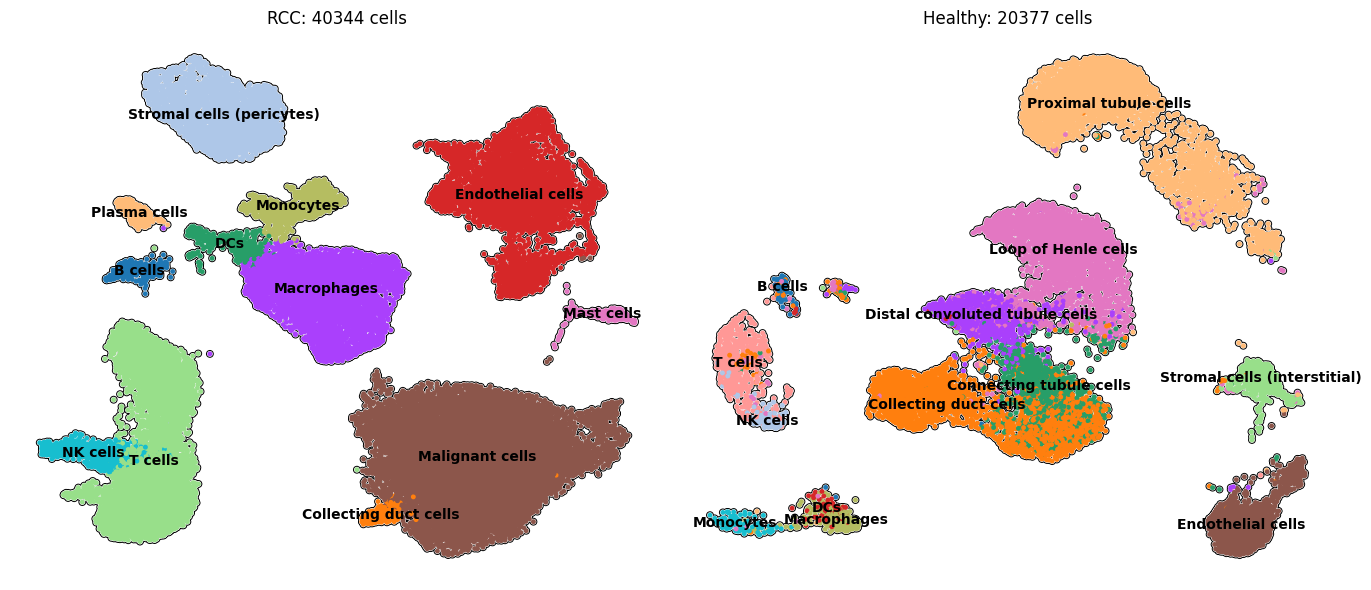

In [7]:
paired_umap(rcc_adata, healthy_adata)

In [37]:
# Differentially expressed genes
sc.tl.rank_genes_groups(
    rcc_adata,
    groupby="CellType",
    method="wilcoxon"
) 

sc.tl.rank_genes_groups(
    healthy_adata,
    groupby="CellType",
    method="wilcoxon",
    use_raw=False,
    layer='log1p'
)

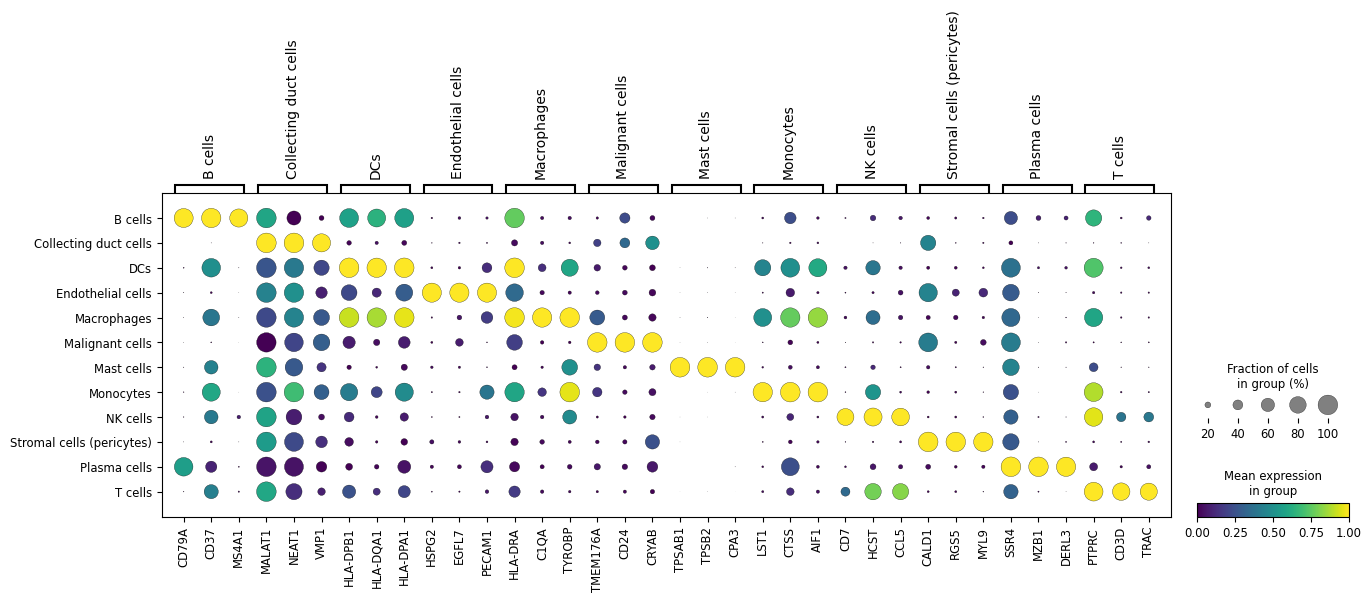

In [53]:
plot_dotplot(rcc_adata, n_genes=3)

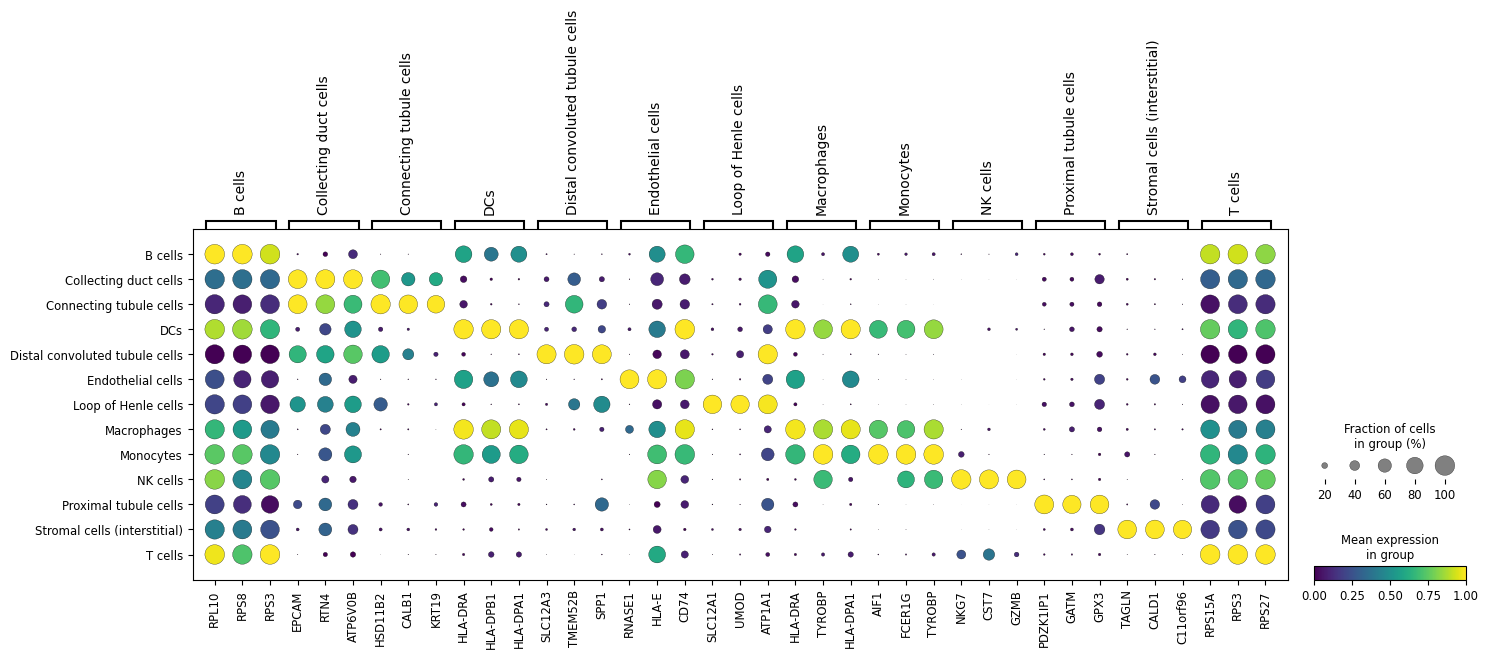

In [52]:
plot_dotplot(healthy_adata, n_genes=3, rcc=False)

In [56]:
rcc_adata = predictor.predict(rcc_adata,
                             groupby='CellType',
                             embedding_key='X_pca_harmony',
                             embedding_dims=30)

Configuration: 40344 cells, 25101 genes, 159 eligible miRNAs
Predicting 156/159 miRNAs; 3/159 not be predicted due to insufficient features in the current dataset


Predicting miRNAs:   0%|          | 0/156 [00:00<?, ?mir/s]

In [70]:
healthy_adata = predictor.predict(healthy_adata,
                             groupby='CellType',
                             embedding_key='X_pca_harmony',
                             embedding_dims=30)

Configuration: 20377 cells, 26837 genes, 159 eligible miRNAs
Predicting 155/159 miRNAs; 4/159 not be predicted due to insufficient features in the current dataset


Predicting miRNAs:   0%|          | 0/155 [00:00<?, ?mir/s]

In [24]:
# List of predicted miRNAs
predicted_mirs = rcc_adata.uns['mirna_prediction']['predicted_mirnas']
len(predicted_mirs)

156

In [78]:
rcc_adata.write(data_path / 'RCC_predicted.h5ad')
healthy_adata.write(data_path / 'control_kidney_healthy_predicted.h5ad')

### Differentially expressed genes

In [22]:
de = predictor.differential_expression(
    rcc_adata,
    groupby="CellType",       
    method="wilcoxon",        
    reference=None,            
    # reference="Malignan cells", # if needed   
    mirnas=None,              
    min_cells=3,
    adjust="fdr_bh",
)

In [23]:
de.head()

,mirna,group,reference,log2fc,auroc,mean_cpm_group,mean_cpm_reference,pval,pval_adj,n_cells_group,n_cells_reference,test_level
0,hsa-mir-23b-3p,B cells,_rest_,-1.668886,0.072287,1413.141292,4495.530552,5.702660e-178,8.896150e-176,372,39972,cell
1,hsa-mir-92a-3p,B cells,_rest_,1.550010,0.913320,66306.475686,22643.518510,2.491325e-166,1.943234e-164,372,39972,cell
2,hsa-mir-25-3p,B cells,_rest_,1.518180,0.909212,50951.615744,17787.892669,4.423221e-163,2.300075e-161,372,39972,cell
3,hsa-mir-425-5p,B cells,_rest_,1.192715,0.901596,2085.789518,911.926372,3.845641e-157,1.499800e-155,372,39972,cell
4,hsa-mir-193b-3p,B cells,_rest_,-2.134118,0.107527,27.132893,122.494592,3.562821e-150,1.111600e-148,372,39972,cell


### Find markers for each cluster

In [26]:
mk = predictor.find_markers(rcc_adata, groupby="CellType") 

In [27]:
mk

,group,mirna,rank,is_marker,log2fc_vs_next,auroc_vs_next,log2fc_vs_rest,auroc_vs_rest,next_group,mean_cpm_group,mean_cpm_next,n_cells_group
0,B cells,hsa-mir-92a-1-5p,1,True,1.371422,0.748503,1.951781,0.803526,NK cells,79.740038,30.206832,372
1,Endothelial cells,hsa-mir-379-5p,1,True,1.439934,0.776960,2.457920,0.916978,Stromal cells (pericytes),27.856330,9.635985,5654
2,Endothelial cells,hsa-let-7b-5p,2,True,0.803314,0.709771,1.079313,0.766091,Stromal cells (pericytes),14249.449833,8164.955315,5654
3,Endothelial cells,hsa-mir-424-5p,3,True,0.654237,0.721551,1.088111,0.826721,Collecting duct cells,252.899781,160.330884,5654
4,Endothelial cells,hsa-mir-656-3p,4,True,0.606877,0.793834,0.773885,0.854860,NK cells,1.427973,0.594247,5654
5,Endothelial cells,hsa-let-7e-5p,5,True,0.541496,0.767309,1.637368,0.942861,Stromal cells (pericytes),5503.505283,3780.914766,5654
6,Endothelial cells,hsa-mir-99b-5p,6,True,0.433579,0.750236,1.875453,0.973325,Stromal cells (pericytes),18563.747557,13744.756694,5654
7,Malignant cells,hsa-mir-194-5p,1,True,2.025995,0.912690,2.734322,0.974183,Collecting duct cells,3281.338465,804.931555,16468
8,Malignant cells,hsa-mir-592,2,True,1.343195,0.733814,3.311924,0.942307,Collecting duct cells,15.037694,5.321207,16468
9,Malignant cells,hsa-mir-106a-5p,3,True,0.912998,0.736524,1.497239,0.844374,DCs,132.372680,69.831598,16468


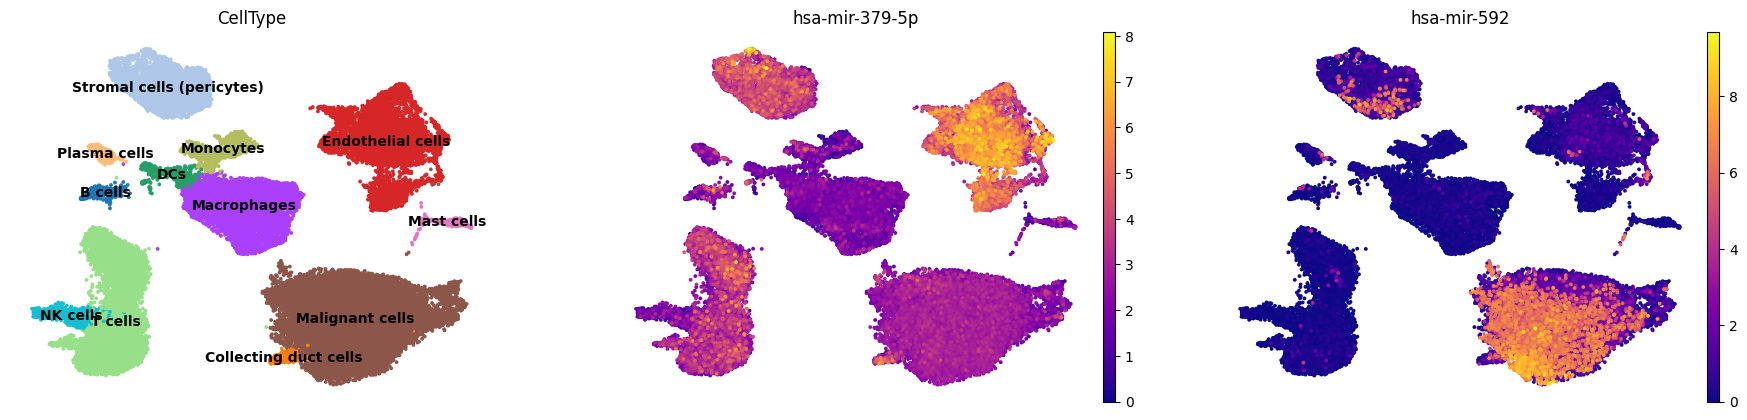

In [34]:
sc.pl.umap(rcc_adata, color=['CellType', 'hsa-mir-379-5p', 'hsa-mir-592'], legend_loc="on data", size=30, alpha=1, frameon=False, cmap='plasma')

### compare renal cancer vs healthy kidney

In [4]:
mirs =['hsa-mir-210-3p', 
        'hsa-mir-26a-5p', 
        'hsa-mir-31-3p', 
        'hsa-mir-196a-5p', 
        'hsa-mir-142-3p', 
        'hsa-mir-25-3p', 
        'hsa-mir-592', 
        'hsa-mir-135b-5p',
        'hsa-mir-615-3p', 
        'hsa-mir-145-5p', 
]


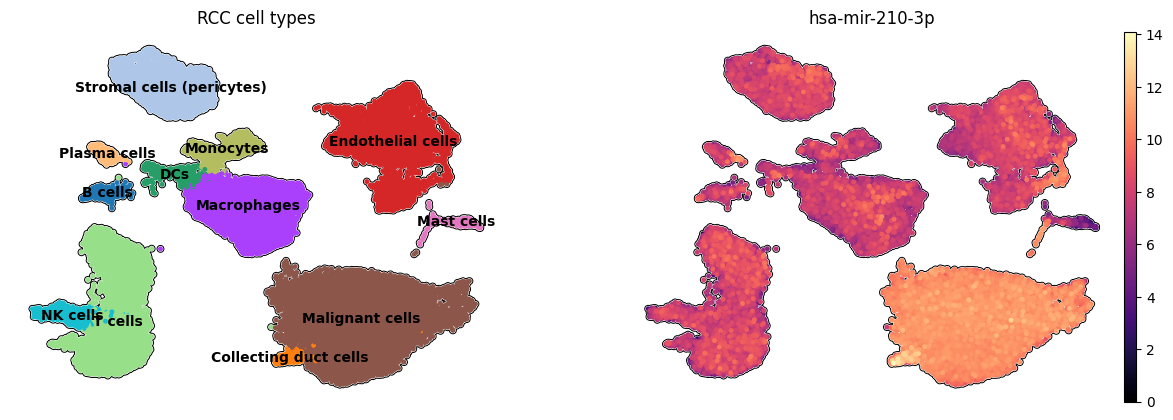

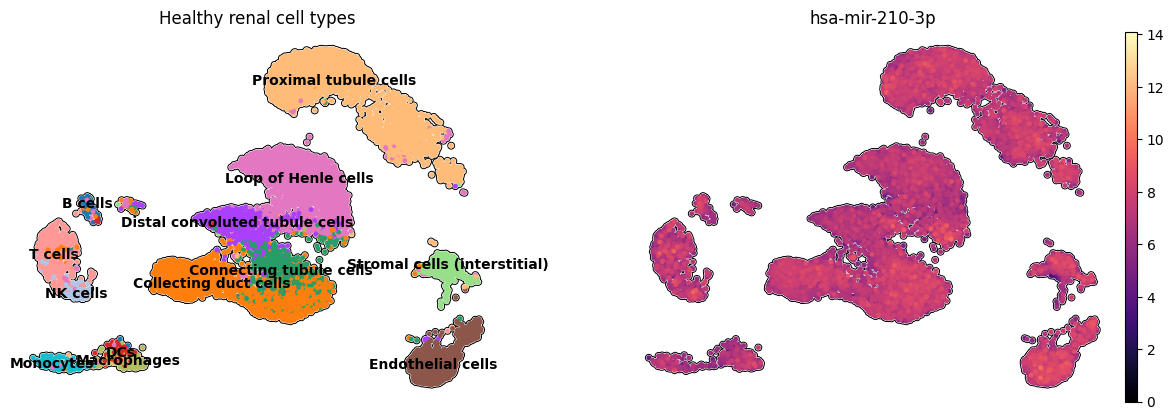

In [7]:
mir = mirs[0]
plot_paired_umap_expression(rcc_adata, healthy_adata, mir, cmap="magma", size=50, alpha=1)

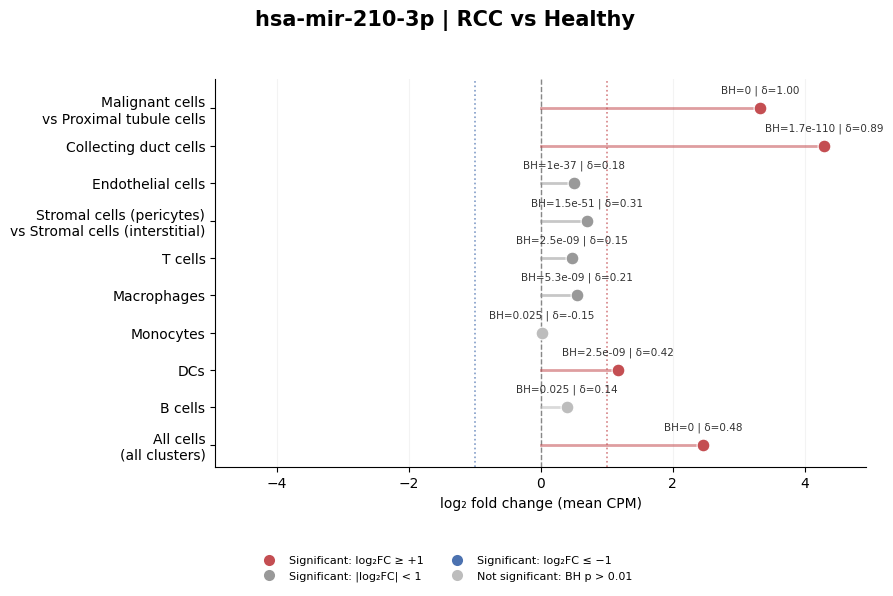

In [11]:
x = rcc_adata.obs[['CellType'] + [mir for mir in rcc_adata.obs.columns if mir.startswith('hsa')]] 
y = healthy_adata.obs[['CellType'] + [mir for mir in healthy_adata.obs.columns if mir.startswith('hsa')]] 


cluster_pairs = [
    ("Malignant cells", "Proximal tubule cells"),
    ("Collecting duct cells", "Collecting duct cells"),
    ("Endothelial cells", "Endothelial cells"),
    ("Stromal cells (pericytes)", "Stromal cells (interstitial)"),
    ("T cells", "T cells"),
    ("Macrophages", "Macrophages"),
    ("Monocytes", "Monocytes"),
    ("DCs", "DCs"),
    ("B cells", "B cells"),  
]


stats = compare_expression_across_clusters(
    df1=x,
    df2=y,
    gene=mir,
    cluster_pairs=cluster_pairs,
    malignant_color="#C44E52",
    healthy_color="#4C72B0",
)